# Week 5 - The main comparison: central vs federated, plus a client reassignment

**Goal:** evaluate a *frozen* comparison of logistic regression, the central MLP and FedAvg on the test users, and run one
controlled experiment that changes only *which windows each client holds*.

## This week tasks

**1. Choose, freeze, then test - in that order.** Until now every decision used validation users only. This week the test
users are scored for the first time. To keep that score honest:
* choose between the two FedAvg candidates (1 vs 3 local epochs) using **validation only**,
* **freeze** the chosen configuration, the checkpoint rule and the exact list of test windows in a file,
* only then load the test windows and score every method on **exactly the same windows** with the same metrics.

After the test scores exist, nothing may be changed because of them. If FedAvg loses, that is the result
("report negative or null results without further test-driven tuning").

**2. Report cost next to the score.** Central MLP, logistic regression and FedAvg do very different amounts of work, so each
result row also records *training updates* and *runtime*. This is a **bounded practical comparison** (what each method reached
under our fixed budget), not a proof that one method is better at equal compute.

**3. Heterogeneity: measure, don't assume.** "Federated data is non-IID" is often said without evidence. We measure it on
the training clients: client sizes, class proportions (label skew) and feature distributions (feature skew - same activity,
different movement style). WISDM participants have almost all 18 activities, so expect *little label skew* but possibly
*clear feature differences*.

**4. The reassignment experiment (a controlled experiment).** Pool all 9,321 training windows, shuffle them, and deal them
back out into 31 *artificial* clients with exactly the original client sizes. Everything else stays fixed: scaler, initial
weights, training settings, validation/test windows and even the client-sampling schedule. The **only** change is client
composition: each artificial client now holds a random mix of people. Comparing FedAvg on original vs reassigned clients
shows how much person-level heterogeneity costs FedAvg. It does **not** create perfectly IID data and is **not** a
realistic deployment (a real person's data cannot be spread over strangers' phones).


## Part 0 - Setup 
### Settings

In [4]:
from pathlib import Path
import json, copy, time, re, hashlib, platform
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix

# ---- Paths --------------------------------------------------------------------
PROJECT       = Path.cwd()                              # run the notebook from the repo root
FEATURE_TABLE = PROJECT / "features_watch.parquet"
SPLIT_FILE    = PROJECT / "split_manifest.csv"
WEEK3         = PROJECT / "WISDM_baseline_outputs"       # scaler, initial weights, central models
WEEK4         = PROJECT / "WISDM_fedavg_outputs"         # runtime budget, prototype history
OUTPUT        = PROJECT / "WISDM_week5_outputs"          # every Week 5 file goes here
CHECKPOINTS   = OUTPUT / "checkpoints"
CHECKPOINTS.mkdir(parents=True, exist_ok=True)

# ---- Frozen settings ----------------------------------------------------------------
SEED              = 42
HIDDEN            = 128
BATCH_SIZE        = 64
CLIENTS_PER_ROUND = 10
CANDIDATE_EPOCHS  = [1, 3]        # the two FedAvg candidates: E=1 and E=3 local epochs
REASSIGN_SEED     = SEED          # seed for the reassignment shuffle

# FedAvg learning rate. The protocol says both candidates use 0.01. Change this ONLY if your advisor decided
# otherwise in the meeting - and then write the reason in FEDAVG_LR_NOTE (it is saved in the run configuration).
FEDAVG_LR      = 0.01
FEDAVG_LR_NOTE = "protocol value: both FedAvg candidates at lr 0.01"

# Round cap: read from the decision you froze in Week 4 (never re-typed by hand).
budget_text = (WEEK4 / "runtime_budget.md").read_text(encoding="utf-8")
cap = re.search(r"Final round cap for Week 5: \*\*(\d+)\*\*", budget_text)
assert cap, "could not find 'Final round cap for Week 5: **N**' in runtime_budget.md"
ROUNDS = int(cap.group(1))

torch.set_num_threads(1)

label_map   = json.loads((WEEK3 / "label_map.json").read_text())
LABELS      = [d["code"] for d in label_map["labels"]]
LABEL_IDS   = [d["id"] for d in label_map["labels"]]
LABEL_NAMES = {d["code"]: d["name"] for d in label_map["labels"]}
FEATURES    = label_map["feature_order"]
LABEL_TO_ID = {c: i for i, c in zip(LABEL_IDS, LABELS)}
assert LABELS == list("ABCDEFGHIJKLMOPQRS") and LABEL_IDS == list(range(18)) and len(FEATURES) == 30

def rel(path):
    # Store paths relative to the project when possible, so configs stay valid on another machine.
    path = Path(path)
    try:
        return str(path.relative_to(PROJECT))
    except ValueError:
        return str(path)

print(f"FedAvg: {ROUNDS} rounds, lr {FEDAVG_LR}, candidates E={CANDIDATE_EPOCHS} | outputs -> {OUTPUT}")

FedAvg: 100 rounds, lr 0.01, candidates E=[1, 3] | outputs -> C:\Users\Daniel Busing\Desktop\Personal\China-Internship\NCP-Wearables\WISDM_week5_outputs


### Week 3 consistency check
The central MLP we test must be the one the **grid search** selected. 

In [5]:
mlp_cfg = json.loads((WEEK3 / "mlp_config.json").read_text())
grid = pd.read_csv(WEEK3 / "lr_grid_search.csv")
grid_best = grid.sort_values(["best_val_macro_f1", "best_epoch", "lr"], ascending=[False, True, True]).iloc[0]

tried = sorted(mlp_cfg["learning_rates_tried"])
assert len(tried) == len(grid) and np.allclose(tried, sorted(grid["lr"])), (
    f"Week 3 outputs are out of date: mlp_config.json lists lrs {tried}, the grid search used {sorted(grid['lr'])}. "
    "Restart & Run All NCP-WISDM-Baselines.ipynb, then re-run this notebook.")
assert np.isclose(mlp_cfg["selected_lr"], grid_best["lr"]), "mlp_selected.pt is not the grid-search winner - re-run Week 3"

central_val = pd.read_csv(WEEK3 / "central_validation.csv").set_index("model")
print(f"Central MLP: lr {mlp_cfg['selected_lr']}, epoch {mlp_cfg['selected_epoch']}, "
      f"validation Macro F1 {mlp_cfg['selected_val_macro_f1']:.4f}")
print(f"Logistic regression: validation Macro F1 {central_val.loc['logreg', 'macro_f1']:.4f}")

Central MLP: lr 0.075, epoch 39, validation Macro F1 0.7238
Logistic regression: validation Macro F1 0.6623


### Data, clients and validation set
Only **window IDs** of the test users are kept here (for the freeze in Part 1). Their features are not touched until Part 4.

`build_clients(assignment)` turns a table of *(row, client)* pairs into the client dictionary used by FedAvg. The same
function builds the original clients now and the reassigned clients in Part 3 - so the two can only differ in *who holds
which windows*.

In [12]:
frame = pd.read_parquet(FEATURE_TABLE)
split_manifest = pd.read_csv(SPLIT_FILE)
split_manifest["split"] = split_manifest["split"].replace({"eval": "validation"})
SPLIT_OF_USER = dict(zip(split_manifest["Subject_ID"], split_manifest["split"]))
frame["split"] = frame["Subject_ID"].map(SPLIT_OF_USER)
assert frame["window_id"].is_unique and frame["split"].notna().all()

# Test users: IDs only (frozen in Part 1). Features stay unused until Part 4.
TEST_IDS = frame.loc[frame["split"] == "test", ["window_id", "Subject_ID", "Activity_Code"]].reset_index(drop=True)

# Train + validation windows, scaled with the Week 3 scaler (fitted on training users only - never refitted).
trval = frame[frame["split"].isin(["train", "validation"])].reset_index(drop=True)
del frame
trval["y"] = trval["Activity_Code"].map(LABEL_TO_ID).astype(int)
scaler = joblib.load(WEEK3 / "scaler.joblib")
assert list(scaler.feature_names_in_) == FEATURES
X_trval = scaler.transform(trval[FEATURES]).astype(np.float32)

# One row per training window; "row" points into X_trval.
train_windows = trval.loc[trval["split"] == "train", ["window_id", "Subject_ID", "Activity_Code", "y"]].copy()
train_windows["row"] = train_windows.index
CLIENT_IDS = sorted(train_windows["Subject_ID"].unique().tolist())

def build_clients(assignment):
    # assignment: DataFrame with columns "row" and "client"  ->  {client: {"X", "y", "n", "rows"}}
    clients = {}
    for c in sorted(assignment["client"].unique()):
        rows = assignment.loc[assignment["client"] == c, "row"].to_numpy()
        clients[c] = {"X": torch.tensor(X_trval[rows]),
                      "y": torch.tensor(trval.loc[rows, "y"].to_numpy(), dtype=torch.long),
                      "n": len(rows), "rows": rows}
    return clients

ORIGINAL_CLIENTS = build_clients(train_windows.assign(client=train_windows["Subject_ID"]))
N_K = {u: c["n"] for u, c in ORIGINAL_CLIENTS.items()}

display(ORIGINAL_CLIENTS)

val_rows = np.flatnonzero((trval["split"] == "validation").to_numpy())
X_val_t = torch.tensor(X_trval[val_rows])
y_val_t = torch.tensor(trval.loc[val_rows, "y"].to_numpy(), dtype=torch.long)
y_val, users_val = y_val_t.numpy(), trval.loc[val_rows, "Subject_ID"].to_numpy()

assert len(CLIENT_IDS) == 31 and sum(N_K.values()) == len(train_windows) == 9321
assert not set(CLIENT_IDS) & set(users_val) and not set(CLIENT_IDS) & set(TEST_IDS["Subject_ID"])
print(f"{len(CLIENT_IDS)} clients / {len(train_windows)} training windows | "
      f"validation {len(set(users_val))} users / {len(y_val)} windows | test IDs {len(TEST_IDS)} (features unused)")

{np.int64(1604): {'X': tensor([[ 1.8432e+00,  7.2149e-01,  8.7614e-01,  ..., -1.8795e+00,
            1.4371e+00,  2.1252e+00],
          [ 1.8248e+00,  8.8597e-01,  7.4129e-01,  ..., -1.9857e+00,
            1.1616e+00,  1.9939e+00],
          [ 1.7931e+00,  9.5674e-01,  6.0705e-01,  ..., -1.6225e+00,
            1.2193e+00,  2.0977e+00],
          ...,
          [ 1.3487e+00, -3.2219e-01,  1.2116e+00,  ..., -2.1961e-01,
            7.6020e-01,  1.2819e-01],
          [ 9.4650e-01,  4.0305e-01,  1.8986e-03,  ..., -1.5059e+00,
            2.6557e+00,  1.3136e+00],
          [ 8.0578e-01,  9.2168e-01,  1.1978e-01,  ..., -1.4266e+00,
            2.0112e+00,  1.3950e+00]]),
  'y': tensor([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  1,
           1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  2,  2,
           2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  3,  3,  3,
           3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  4,

31 clients / 9321 training windows | validation 10 users / 3060 windows | test IDs 3049 (features unused)


### Model, initial weights and evaluator (same as Weeks 3-4)
`evaluate_state` scores a state_dict on the **validation** users only - FedAvg uses it every round. The test set gets its own code path in Part 4, so it cannot be scored by accident.

In [4]:
class MLP(nn.Module):
    def __init__(self, n_in=len(FEATURES), n_hidden=HIDDEN, n_out=len(LABELS)):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_in, n_hidden), nn.ReLU(), nn.Linear(n_hidden, n_out))

    def forward(self, x):
        return self.net(x)

loss_fn = nn.CrossEntropyLoss()
INITIAL_STATE = torch.load(WEEK3 / "mlp_initial_state.pt")     # w_0, shared by every MLP and FedAvg run

def predict_logits(model, X):
    model.eval()
    with torch.no_grad():
        return model(X)

def evaluate(y_true, y_pred, subjects):
    # Pooled metrics and per-user metrics are computed SEPARATELY (two different summaries).
    y_true, y_pred, subjects = map(np.asarray, (y_true, y_pred, subjects))
    per_user_f1 = pd.Series({u: f1_score(y_true[subjects == u], y_pred[subjects == u],
                                         labels=LABEL_IDS, average="macro", zero_division=0)
                             for u in np.unique(subjects)})
    return {
        "macro_f1": f1_score(y_true, y_pred, labels=LABEL_IDS, average="macro", zero_division=0),
        "accuracy": accuracy_score(y_true, y_pred),
        "mean_user_macro_f1": per_user_f1.mean(),
        "min_user_macro_f1": per_user_f1.min(),
        "max_user_macro_f1": per_user_f1.max(),
        "n_windows": len(y_true),
        "n_users": len(per_user_f1),
        "_per_user_f1": per_user_f1,
        "_confusion": confusion_matrix(y_true, y_pred, labels=LABEL_IDS),
    }

def evaluate_state(state):
    # VALIDATION ONLY.
    model = MLP()
    model.load_state_dict(state)
    logits = predict_logits(model, X_val_t)
    result = evaluate(y_val, logits.argmax(1).numpy(), users_val)
    result["val_loss"] = loss_fn(logits, y_val_t).item()
    return result

init = evaluate_state(INITIAL_STATE)
week3_epoch0 = pd.read_csv(WEEK3 / "mlp_history.csv").query("epoch == 0").val_macro_f1.iloc[0]
assert np.isclose(init["macro_f1"], week3_epoch0), "initial weights / scaler differ from Week 3"
print(f"Initial model validation Macro F1 {init['macro_f1']:.4f} (matches Week 3)")

Initial model validation Macro F1 0.0331 (matches Week 3)


###  Your Week 4 FedAvg functions
 Week 4 functions, copied unchanged except for one refactor in `run_fedavg`:
it now takes the clients as a **parameter** (`clients`) instead of reading the global `CLIENTS` / `CLIENT_IDS` / `N_K`.
Checkpoints go to `checkpoints/<tag>/roundNNN.pt`, and progress prints every 10 rounds.

In [6]:
def sample_clients(rng, client_ids, k=CLIENTS_PER_ROUND):
    samples = rng.choice(client_ids, size=min(k, len(client_ids)), replace=False)
    return sorted(samples.tolist())

def local_train(global_state, X, y, lr, epochs, seed):
    model = MLP()
    model.load_state_dict(global_state)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.0)
    loader = DataLoader(TensorDataset(X, y), batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    total_loss, seen = 0.0, 0
    for epoch in range(epochs):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(yb)
            seen += len(yb)
    return copy.deepcopy(model.state_dict()), total_loss / seen

def aggregate(states, counts):
    total = sum(counts)
    new_state = {}
    for name in states[0]:
        new_state[name] = sum(n * s[name] for s, n in zip(states, counts)) / total
    return new_state

HISTORY_COLUMNS = ["round", "selected_users", "sample_counts", "total_samples", "mean_local_loss",
                   "val_macro_f1", "val_accuracy", "val_mean_user_macro_f1", "val_loss", "round_time_s", "elapsed_s"]

def run_fedavg(n_rounds, clients, lr, local_epochs, clients_per_round=CLIENTS_PER_ROUND, seed=SEED, tag="fedavg"):
    client_ids = sorted(clients)                       # the client "slots"
    ckpt_dir = CHECKPOINTS / tag
    ckpt_dir.mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(seed)
    global_state = copy.deepcopy(INITIAL_STATE)
    t_start = time.perf_counter()
    scores = evaluate_state(global_state)
    rows = [{"round": 0, "selected_users": "", "sample_counts": "", "total_samples": 0, "mean_local_loss": np.nan,
             "val_macro_f1": scores["macro_f1"], "val_accuracy": scores["accuracy"],
             "val_mean_user_macro_f1": scores["mean_user_macro_f1"], "val_loss": scores["val_loss"],
             "round_time_s": time.perf_counter() - t_start, "elapsed_s": time.perf_counter() - t_start}]
    for r in range(1, n_rounds + 1):
        r_round = time.perf_counter()
        selected = sample_clients(rng, client_ids, clients_per_round)
        client_states, client_loss = [], []
        for user in selected:
            state, loss = local_train(global_state, clients[user]["X"], clients[user]["y"],
                                      lr=lr, epochs=local_epochs, seed=seed + 2000 * r + user)
            client_states.append(state)
            client_loss.append(loss)
        counts = [clients[user]["n"] for user in selected]
        global_state = aggregate(client_states, counts)
        scores = evaluate_state(global_state)
        torch.save(global_state, ckpt_dir / f"round{r:03d}.pt")
        rows.append({"round": r, "selected_users": ";".join(map(str, selected)),
                     "sample_counts": ";".join(map(str, counts)), "total_samples": sum(counts),
                     "mean_local_loss": np.average(client_loss, weights=counts),
                     "val_macro_f1": scores["macro_f1"], "val_accuracy": scores["accuracy"],
                     "val_mean_user_macro_f1": scores["mean_user_macro_f1"], "val_loss": scores["val_loss"],
                     "round_time_s": time.perf_counter() - r_round, "elapsed_s": time.perf_counter() - t_start})
        if r % 10 == 0 or r == n_rounds:
            print(f"  [{tag}] round {r:>3}: val Macro F1 {scores['macro_f1']:.4f}  ({time.perf_counter() - t_start:.1f} s)")
    return pd.DataFrame(rows)[HISTORY_COLUMNS], global_state

## Part 1 - FedAvg candidates, selection and freeze

### Run both candidates 
Same clients, same initial weights, same lr, same client-sampling seed - only the number of local epochs differs.
The E=1 run must reproduce your Week 4 prototype exactly for rounds 1-10 (a check that the copied code is unchanged).

Running fedavg_E1: 100 rounds, 1 local epoch(s), lr 0.01
  [fedavg_E1] round  10: val Macro F1 0.1352  (2.5 s)
  [fedavg_E1] round  20: val Macro F1 0.2199  (3.3 s)
  [fedavg_E1] round  30: val Macro F1 0.2487  (4.1 s)
  [fedavg_E1] round  40: val Macro F1 0.2744  (5.0 s)
  [fedavg_E1] round  50: val Macro F1 0.3147  (5.8 s)
  [fedavg_E1] round  60: val Macro F1 0.3343  (6.5 s)
  [fedavg_E1] round  70: val Macro F1 0.3478  (7.2 s)
  [fedavg_E1] round  80: val Macro F1 0.3597  (7.9 s)
  [fedavg_E1] round  90: val Macro F1 0.3818  (8.7 s)
  [fedavg_E1] round 100: val Macro F1 0.3962  (9.6 s)
Running fedavg_E3: 100 rounds, 3 local epoch(s), lr 0.01
  [fedavg_E3] round  10: val Macro F1 0.2436  (1.7 s)
  [fedavg_E3] round  20: val Macro F1 0.3320  (3.1 s)
  [fedavg_E3] round  30: val Macro F1 0.3854  (4.8 s)
  [fedavg_E3] round  40: val Macro F1 0.4360  (6.5 s)
  [fedavg_E3] round  50: val Macro F1 0.4759  (8.3 s)
  [fedavg_E3] round  60: val Macro F1 0.5099  (10.1 s)
  [fedavg_E3] round  

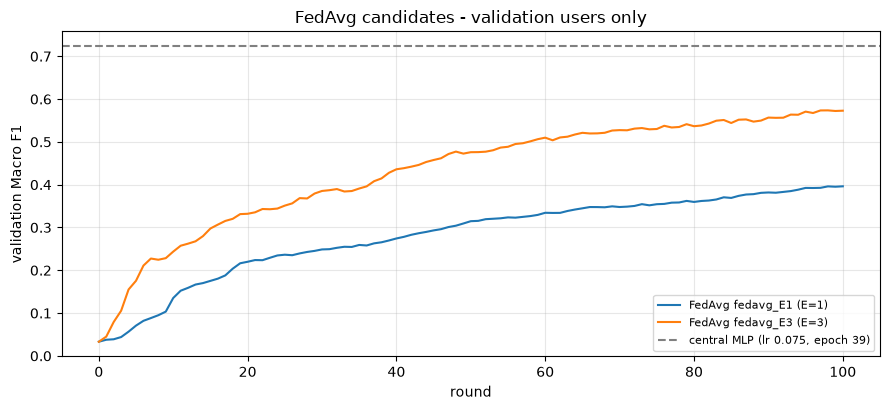

In [7]:
CANDIDATES = {}
for E in CANDIDATE_EPOCHS:
    tag = f"fedavg_E{E}"
    print(f"Running {tag}: {ROUNDS} rounds, {E} local epoch(s), lr {FEDAVG_LR}")
    history, _ = run_fedavg(ROUNDS, ORIGINAL_CLIENTS, lr=FEDAVG_LR, local_epochs=E, seed=SEED, tag=tag)
    history.to_csv(OUTPUT / f"history_{tag}.csv", index=False)
    CANDIDATES[tag] = {"local_epochs": E, "history": history}

# Reproducibility check against Week 4 (only meaningful if the lr is the Week 4 lr).
if FEDAVG_LR == 0.01:
    proto = pd.read_csv(WEEK4 / "prototype_history.csv")
    h1 = CANDIDATES["fedavg_E1"]["history"].iloc[:len(proto)]
    assert np.allclose(h1["val_macro_f1"], proto["val_macro_f1"]), "E=1 run does not reproduce the Week 4 prototype"
    print("OK: rounds 0-10 of the E=1 run reproduce the Week 4 prototype exactly")

# Validation curves of both candidates, with the central MLP for reference.
fig, ax = plt.subplots(figsize=(9, 4.2))
for tag, c in CANDIDATES.items():
    h = c["history"]
    ax.plot(h["round"], h["val_macro_f1"], label=f"FedAvg {tag} (E={c['local_epochs']})")
ax.axhline(mlp_cfg["selected_val_macro_f1"], ls="--", c="grey",
           label=f"central MLP (lr {mlp_cfg['selected_lr']}, epoch {mlp_cfg['selected_epoch']})")
ax.set(xlabel="round", ylabel="validation Macro F1", title="FedAvg candidates - validation users only")
ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUTPUT / "fedavg_candidates.png", dpi=150); plt.show()

### `best_round` and choosing the candidate

**Checkpoint rule (frozen):** for each run, the best round is the one with the highest validation Macro F1, excluding round 0;
ties -> the **earliest** round.
**Candidate rule (frozen):** choose the candidate with the highest best-round validation Macro F1; ties -> the earlier best
round, then the smaller number of local epochs (less compute).

1. Write `best_round(history)` returning `(round, val_macro_f1)` as plain Python `int` and `float`.
2. Build `selection`: a DataFrame with one row per candidate and columns `tag, local_epochs, best_round, best_val_macro_f1`.
3. Set `SELECTED_TAG` to the chosen candidate's tag (e.g. `"fedavg_E3"`).

<details><summary>Hint 1</summary>

You wrote this exact rule in Week 4 for the prototype checkpoint: keep `round >= 1`, find the max with `.max()`, find all
rounds that are `np.isclose` to it, take `.min()` of their round numbers.
</details>

<details><summary>Hint 2</summary>

For `selection`, loop over `CANDIDATES.items()` and append one dict per candidate, then `pd.DataFrame(rows)`.
For the choice: `selection.sort_values(["best_val_macro_f1", "best_round", "local_epochs"], ascending=[False, True, True])`
and take the first row's `tag`.
</details>

In [11]:
def best_round(history):
    """Return (round, val_macro_f1) of the best validation round (round 0 excluded); ties -> earliest round."""
    trained = history[history["round"] >= 1]
    best_f1 = trained["val_macro_f1"].max()
    best_round = int(trained.loc[np.isclose(trained["val_macro_f1"], best_f1), "round"].min()) #Keep the smaller round if equal
    best_round_f1 = float(trained.set_index("round").loc[best_round, "val_macro_f1"])
    return best_round, best_round_f1

rows = []

for tag, candidate in CANDIDATES.items():
    r, f1 = best_round(candidate["history"])
    rows.append({"tag": tag, "local_epochs": candidate["local_epochs"], "best_round": r, "best_val_macro_f1": f1})

selection = pd.DataFrame(rows)
display(selection)

ranked = selection.sort_values(["best_val_macro_f1", "best_round", "local_epochs"], ascending=[False, True, True]) #Highest f1 First, then Earlier round, then fewer epochs
SELECTED_TAG = ranked.iloc[0]["tag"]
print("Selected FedAvg candidate:", SELECTED_TAG)

,tag,local_epochs,best_round,best_val_macro_f1
0,fedavg_E1,1,100,0.396202
1,fedavg_E3,3,98,0.573629


Selected FedAvg candidate: fedavg_E3


In [12]:
# TEST (PROVIDED)
toy = pd.DataFrame({"round": [0, 1, 2, 3, 4], "val_macro_f1": [0.99, 0.50, 0.70, 0.70, 0.60]})
assert best_round(toy) == (2, 0.70), "round 0 must be excluded and ties must go to the EARLIEST round"
r_, f_ = best_round(CANDIDATES["fedavg_E1"]["history"])
assert isinstance(r_, int) and isinstance(f_, float), "return plain int and float"
assert set(["tag", "local_epochs", "best_round", "best_val_macro_f1"]) <= set(selection.columns)
assert len(selection) == len(CANDIDATES) and SELECTED_TAG in CANDIDATES
expected = selection.sort_values(["best_val_macro_f1", "best_round", "local_epochs"], ascending=[False, True, True]).iloc[0]
assert SELECTED_TAG == expected["tag"], "SELECTED_TAG does not follow the candidate rule"
print("OK selection:", SELECTED_TAG)

OK selection: fedavg_E3


### `fedavg_local_steps` - counting training updates

To report cost next to the score we count **client SGD steps**: in every round, each selected client takes
`ceil(n_k / BATCH_SIZE)` steps per local epoch (the last, smaller batch is still one step).

Write `fedavg_local_steps(history, up_to_round, local_epochs)` = the total over rounds `1 ... up_to_round` and over each
round's selected clients of `ceil(n_k / BATCH_SIZE) * local_epochs`. The `n_k` of each round are in the history's
`sample_counts` column (e.g. `"306;295;..."`).

For comparison (provided later): the central MLP takes `146` steps per epoch; FedAvg additionally has
`up_to_round` *global* updates (one aggregation per round).

<details><summary>Hint</summary>

Filter the rows with `1 <= round <= up_to_round`. For each row: `counts = [int(n) for n in row.sample_counts.split(";")]`,
then add `sum(math.ceil(n / BATCH_SIZE) for n in counts) * local_epochs` (or `-(-n // BATCH_SIZE)` - integer ceiling
without importing `math`).
</details>

In [18]:
import math

def fedavg_local_steps(history, up_to_round, local_epochs, batch_size=BATCH_SIZE):
    """Total client SGD steps in rounds 1..up_to_round."""
    rows = history[(history["round"] >= 1) & (history["round"] <= up_to_round)]
    total = 0
    for counts_text in rows["sample_counts"]:
        counts = [int(n) for n in counts_text.split(";")]
        steps_this_round = sum(math.ceil(n / batch_size) for n in counts)
        total += steps_this_round * local_epochs
    return total

In [19]:
# TEST (PROVIDED)
toy = pd.DataFrame({"round": [0, 1, 2], "sample_counts": ["", "306;64", "65"]})
assert fedavg_local_steps(toy, 1, 1) == 5 + 1, "306 windows -> 5 steps, 64 -> 1 step"
assert fedavg_local_steps(toy, 2, 1) == 6 + 2, "65 windows -> 2 steps (the last small batch still counts)"
assert fedavg_local_steps(toy, 2, 3) == 3 * 8, "multiply by local epochs"
assert fedavg_local_steps(toy, 0, 1) == 0
print("OK fedavg_local_steps")

OK fedavg_local_steps


### Freeze
Writes three files **before any test window is scored**:
* `frozen_config.json` - selected FedAvg configuration, checkpoint rules, central models used, test manifest fingerprint,
* `test_window_manifest.csv` - the exact test windows every method will be scored on (plus a SHA-256 fingerprint),
* `run_configs.json` - one entry per run (`run_id`), so **every number in the results can be traced to its run**.

Runtime is the **full** training run of each method (all epochs / all rounds) on this machine.

In [20]:
def save_run_configs():
    (OUTPUT / "run_configs.json").write_text(json.dumps(RUN_CONFIGS, indent=2))

sel = selection.set_index("tag").loc[SELECTED_TAG]
SELECTED_E = int(sel["local_epochs"])
SELECTED_ROUND = int(sel["best_round"])

# Selected FedAvg checkpoint, saved with its metadata (like the Week 4 prototype).
fedavg_ckpt = OUTPUT / "fedavg_selected.pt"
torch.save({"state_dict": torch.load(CHECKPOINTS / SELECTED_TAG / f"round{SELECTED_ROUND:03d}.pt"),
            "tag": SELECTED_TAG, "round": SELECTED_ROUND, "val_macro_f1": float(sel["best_val_macro_f1"]),
            "lr": FEDAVG_LR, "local_epochs": SELECTED_E, "clients_per_round": CLIENTS_PER_ROUND,
            "label_order": LABELS, "feature_order": FEATURES}, fedavg_ckpt)

# Test window manifest + fingerprint.
TEST_IDS.to_csv(OUTPUT / "test_window_manifest.csv", index=False)
TEST_SHA256 = hashlib.sha256("\n".join(sorted(TEST_IDS["window_id"])).encode()).hexdigest()

logreg_model = joblib.load(WEEK3 / "logreg.joblib")
sel_hist = CANDIDATES[SELECTED_TAG]["history"]
RUN_CONFIGS = {
    "logreg_central": {
        "method": "Logistic regression", "clients": "pooled (31 training users)", "kind": "sklearn",
        "checkpoint": rel(WEEK3 / "logreg.joblib"), "selected_at": "converged (lbfgs)",
        "val_macro_f1": float(central_val.loc["logreg", "macro_f1"]),
        "training_updates": int(np.max(logreg_model.n_iter_)), "update_unit": "lbfgs iterations (full-batch)",
        "runtime_s": float(central_val.loc["logreg", "runtime_s"]),
        "settings": {"C": 1.0, "max_iter": 1000}},
    "mlp_central": {
        "method": "Central MLP", "clients": "pooled (31 training users)", "kind": "torch",
        "checkpoint": rel(WEEK3 / "mlp_selected.pt"),
        "selected_at": f"epoch {mlp_cfg['selected_epoch']} of {mlp_cfg['max_epochs']}",
        "val_macro_f1": float(mlp_cfg["selected_val_macro_f1"]),
        "training_updates": int(mlp_cfg["selected_epoch"] * mlp_cfg["updates_per_epoch"]),
        "update_unit": f"SGD steps (batch {BATCH_SIZE}) to the selected epoch",
        "runtime_s": float(mlp_cfg["runtime_s"][str(mlp_cfg["selected_lr"])]),
        "settings": {"lr": mlp_cfg["selected_lr"], "batch_size": BATCH_SIZE, "max_epochs": mlp_cfg["max_epochs"]}},
    SELECTED_TAG: {
        "method": f"FedAvg (E={SELECTED_E})", "clients": "31 original clients (one per training user)", "kind": "torch",
        "checkpoint": rel(fedavg_ckpt), "selected_at": f"round {SELECTED_ROUND} of {ROUNDS}",
        "val_macro_f1": float(sel["best_val_macro_f1"]),
        "training_updates": int(fedavg_local_steps(sel_hist, SELECTED_ROUND, SELECTED_E)),
        "update_unit": f"client SGD steps (batch {BATCH_SIZE}) to the selected round; {SELECTED_ROUND} global rounds",
        "runtime_s": float(sel_hist["elapsed_s"].iloc[-1]),
        "settings": {"lr": FEDAVG_LR, "lr_note": FEDAVG_LR_NOTE, "local_epochs": SELECTED_E,
                     "clients_per_round": CLIENTS_PER_ROUND, "rounds": ROUNDS, "seed": SEED, "batch_size": BATCH_SIZE}},
}
save_run_configs()

frozen = {
    "frozen_at": time.strftime("%Y-%m-%d %H:%M:%S"),
    "machine": platform.node(),
    "fedavg_candidates": selection.to_dict(orient="records"),
    "fedavg_selected": {"tag": SELECTED_TAG, "local_epochs": SELECTED_E, "round": SELECTED_ROUND,
                        "lr": FEDAVG_LR, "lr_note": FEDAVG_LR_NOTE, "rounds_cap": ROUNDS, "checkpoint": rel(fedavg_ckpt)},
    "checkpoint_rule": "max validation pooled Macro F1 (18 labels, zero_division=0), round 0 excluded; ties -> earliest round",
    "candidate_rule": "max best-round validation Macro F1; ties -> earlier best round, then fewer local epochs",
    "central_mlp": {"checkpoint": rel(WEEK3 / "mlp_selected.pt"), "lr": mlp_cfg["selected_lr"], "epoch": mlp_cfg["selected_epoch"]},
    "logreg": {"checkpoint": rel(WEEK3 / "logreg.joblib")},
    "scaler": rel(WEEK3 / "scaler.joblib"), "initial_state": rel(WEEK3 / "mlp_initial_state.pt"),
    "test_manifest": {"file": "test_window_manifest.csv", "n_windows": len(TEST_IDS),
                      "n_users": int(TEST_IDS["Subject_ID"].nunique()), "sha256": TEST_SHA256},
}
(OUTPUT / "frozen_config.json").write_text(json.dumps(frozen, indent=2))
print(json.dumps(frozen["fedavg_selected"], indent=2))
print(f"Test manifest frozen: {len(TEST_IDS)} windows from {TEST_IDS['Subject_ID'].nunique()} users, sha256 {TEST_SHA256[:16]}...")

{
  "tag": "fedavg_E3",
  "local_epochs": 3,
  "round": 98,
  "lr": 0.01,
  "lr_note": "protocol value: both FedAvg candidates at lr 0.01",
  "rounds_cap": 100,
  "checkpoint": "WISDM_week5_outputs\\fedavg_selected.pt"
}
Test manifest frozen: 3049 windows from 10 users, sha256 e619cc79d9d1d197...


## Part 2 - How heterogeneous are the training clients? (training data only)

### Client sizes 

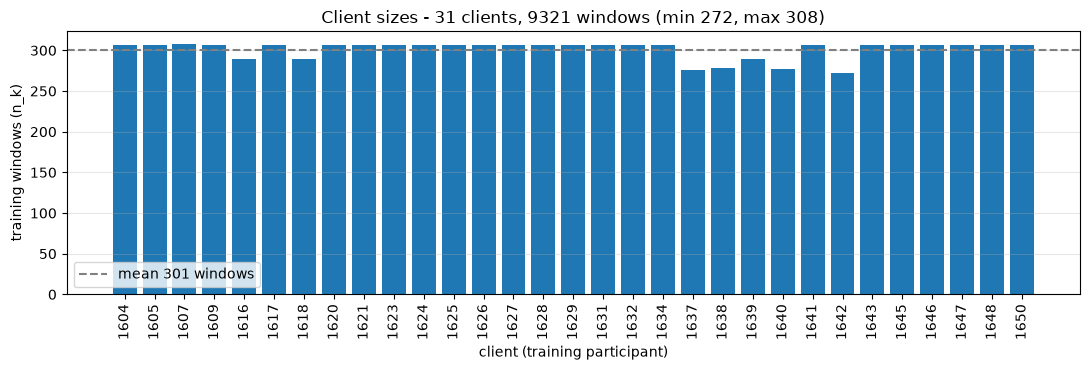

Size ratio largest/smallest: 1.13


In [21]:
sizes = pd.Series(N_K).sort_index()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(sizes.index.astype(str), sizes.values, color="tab:blue")
ax.axhline(sizes.mean(), ls="--", c="grey", label=f"mean {sizes.mean():.0f} windows")
ax.set(xlabel="client (training participant)", ylabel="training windows (n_k)",
       title=f"Client sizes - {len(sizes)} clients, {sizes.sum()} windows (min {sizes.min()}, max {sizes.max()})")
ax.tick_params(axis="x", rotation=90)
ax.legend(); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(OUTPUT / "client_size.png", dpi=150); plt.show()
print(f"Size ratio largest/smallest: {sizes.max() / sizes.min():.2f}")

### 2b. Class proportions and a label-skew measure

1. `client_class_counts(clients)` -> DataFrame, one row per client (index = client ID), one column per label **code** in
   `LABELS` order (all 18, even if a client has none), values = number of windows.
2. `total_variation(counts)` -> Series, one value per client:
   $TV_k = \tfrac{1}{2} \sum_c |p_k(c) - p(c)|$, where $p_k$ is the client's class **proportions** and $p$ is the
   class distribution of all clients pooled. $TV = 0$: same mix as everyone; $TV = 1$: no classes in common.
   (Reference: a client missing 2 of 18 otherwise-balanced classes has TV of about 0.11.)
3. Plot `class_distribution.png`: a heatmap of proportions (clients x classes) and, beside it, the TV per client.
   Mark missing classes so they are easy to see. Put the number of clients/windows in the title.

<details><summary>Hint 1 (counts)</summary>

For one client: `np.bincount(c["y"].numpy(), minlength=len(LABELS))` counts each class ID 0-17. Build a dict
`{client: counts}` and use `pd.DataFrame.from_dict(d, orient="index", columns=LABELS)`.
</details>

<details><summary>Hint 2 (TV)</summary>

`props = counts.div(counts.sum(axis=1), axis=0)` (each row sums to 1); `pooled = counts.sum() / counts.values.sum()`;
`0.5 * (props - pooled).abs().sum(axis=1)`.
</details>

<details><summary>Hint 3 (plot)</summary>

`fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 8), gridspec_kw={"width_ratios": [4, 1]})`;
`ax1.imshow(props.values, aspect="auto", cmap="viridis")`, ticks with `set_xticks(range(18), LABELS)` and
`set_yticks(range(len(props)), props.index)`; mark zeros with `ax1.text(j, i, "x", ...)` where `counts.values[i, j] == 0`;
`ax2.barh(range(len(tv)), tv.values)` and `ax2.invert_yaxis()` so rows line up with the heatmap; add `fig.colorbar(...)`.
</details>

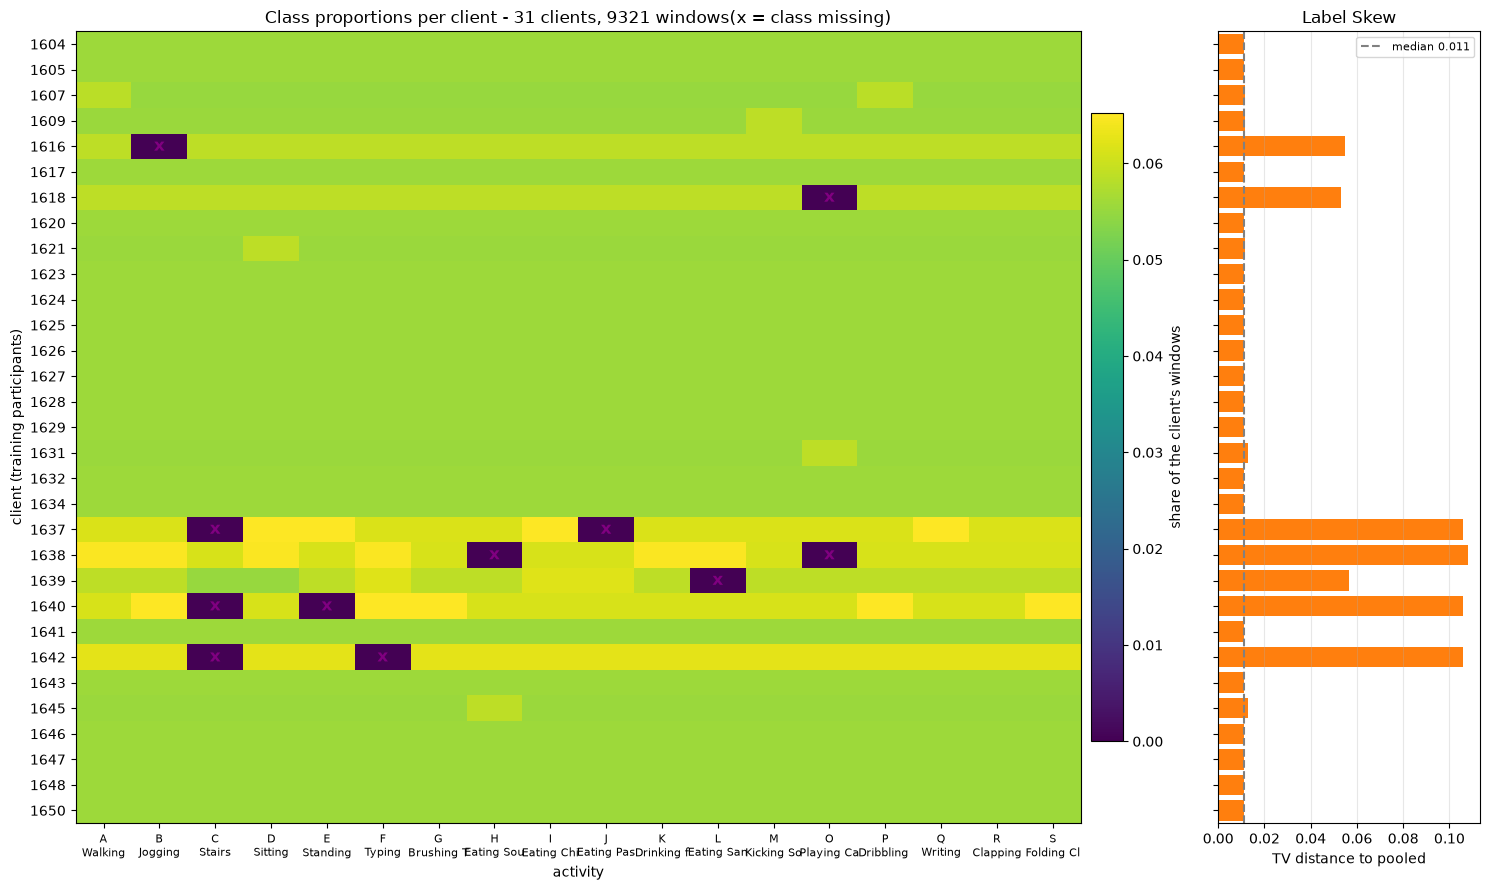

Label skew (TV): median 0.011, max 0.108 (client 1638)
Clients missing at least one class: 7 of 31
  1616: missing B (Jogging) -> TV 0.055
  1618: missing O (Playing Catch with Tennis Ball) -> TV 0.053
  1637: missing C (Stairs), J (Eating Pasta) -> TV 0.106
  1638: missing H (Eating Soup), O (Playing Catch with Tennis Ball) -> TV 0.108
  1639: missing L (Eating Sandwich) -> TV 0.056
  1640: missing C (Stairs), E (Standing) -> TV 0.106
  1642: missing C (Stairs), F (Typing) -> TV 0.106


In [25]:
def client_class_counts(clients):
    """Clients x 18 label codes -> number of windows."""
    d = {}
    for client, c in clients.items():
        client_count = np.bincount(c["y"].numpy(), minlength=len(LABELS))
        d[client] = client_count
        
    return pd.DataFrame.from_dict(d, orient = "index", columns = LABELS) 

def total_variation(counts):
    """Per-client total variation distance between its class proportions and the pooled class proportions."""
    props = counts.div(counts.sum(axis=1), axis=0)
    pooled = counts.sum() / counts.values.sum()
    var = 0.5 * (props - pooled).abs().sum(axis=1)
    return var
    
class_counts = client_class_counts(ORIGINAL_CLIENTS)
tv = total_variation(class_counts)

# plot and save class_distribution.png, then print a short summary (median / max TV, and which clients miss which classes)
props = class_counts.div(class_counts.sum(axis=1), axis =0) # each clients row sums to 1
fig, (ax1, ax2) = plt.subplots(1, 2, figsize= (15,9), sharey = True, 
                               gridspec_kw ={"width_ratios": [4,1]})

# Left: Heatmap of class proportions (row = clients, cols = activities)
im = ax1.imshow(props.values, aspect = "auto", cmap = "viridis")
ax1.set_xticks(range(len(LABELS)), [f"{c}\n{LABEL_NAMES[c][:10]}" for c in LABELS], fontsize = 8)
ax1.set_yticks(range(len(props)), props.index)
ax1.set(xlabel="activity", ylabel="client (training participants)", 
        title = f"Class proportions per client - {len(props)} clients, {int(class_counts.values.sum())} windows"
        f"(x = class missing)")
for i, j in zip(*np.nonzero(class_counts.values == 0)):
    ax1.text(j, i, "x", ha = "center", va = "center", color = "purple",
             fontsize = 12, fontweight = "bold")
fig.colorbar(im, ax = ax1, fraction = 0.03, pad = 0.01, label = "share of the client's windows")

#Right: Label Skew per client (TV distance to pooled class mix), same row order as heatmap
ax2.barh(range(len(tv)), tv.values, color ="tab:orange")
ax2.axvline(tv.median(), ls = "--", c = "grey", label = f"median {tv.median():.3f}")
ax2.set(xlabel="TV distance to pooled", title = "Label Skew")
ax2.legend(fontsize = 8)
ax2.grid(axis="x", alpha = 0.3)

plt.tight_layout()
plt.savefig(OUTPUT/"class_distribution.png", dpi = 150)
plt.show()

# Summary
print(f"Label skew (TV): median {tv.median():.3f}, max {tv.max():.3f} (client {tv.idxmax()})")
missing = {client: "".join(c for c in LABELS if class_counts.loc[client, c] == 0)
           for client in class_counts.index}
missing = {client: codes for client, codes in missing.items() if codes}
print(f"Clients missing at least one class: {len(missing)} of {len(class_counts)}")
for client, codes in missing.items():
    print(f"  {client}: missing {', '.join(f'{c} ({LABEL_NAMES[c]})' for c in codes)} -> TV {tv[client]:.3f}")

In [22]:
# TESTS
assert list(class_counts.columns) == LABELS and len(class_counts) == len(CLIENT_IDS)
assert (class_counts.sum(axis=1) == pd.Series(N_K)).all(), "row sums must equal the client sizes"
toy_tv = total_variation(pd.DataFrame({"a": [1, 3], "b": [1, 1]}))
assert np.allclose(toy_tv.values, [1 / 6, 1 / 12]), "check the TV formula (proportions, pooled, 0.5 * sum |diff|)"
assert ((tv >= 0) & (tv <= 1)).all()
assert (OUTPUT / "class_distribution.png").exists(), "save the plot as class_distribution.png"
print(f"OK class distribution: median TV {tv.median():.3f}, max TV {tv.max():.3f} (client {tv.idxmax()})")

OK class distribution: median TV 0.011, max TV 0.108 (client 1638)


### 2c. Feature heterogeneity

Label proportions can be similar while **how** people move differs. Compare clients on the **scaled** training features
(scaled with the Week 3 scaler, so 0 = the average training window and 1 = one training standard deviation).

1. `client_feature_means(clients)` -> DataFrame, index = client ID, columns = `FEATURES`, values = the mean of each scaled
   feature over that client's windows.
2. `between_within_ratio(clients)` -> Series indexed by `FEATURES`:
   (variance of the 31 client means) / (average of the 31 within-client variances).
   Near 0: clients look alike on that feature; large: clients differ a lot compared with the spread inside one client.
3. Plot `feature_heterogeneity.png`: a heatmap of the client means (diverging colour map centred on 0, e.g.
   `cmap="RdBu_r", vmin=-1.5, vmax=1.5`) and a bar chart of the ratio per feature.

Note: client means mix two effects - movement style **and** the client's activity mix. Since activity mixes are nearly
identical here (Part 2b), large differences point mostly to movement style.

<details><summary>Hint 1</summary>

`c["X"].numpy()` is the client's (n_k x 30) array. `.mean(axis=0)` gives the 30 means, `.var(axis=0)` the 30 variances.
Collect one row per client in a dict and build the DataFrame with `orient="index", columns=FEATURES`.
</details>

<details><summary>Hint 2</summary>

`means.var(axis=0) / within.mean(axis=0)` where `within` is the DataFrame of per-client variances.
</details>

In [8]:
#def client_feature_means(clients):
    #"""Clients x FEATURES -> mean of each scaled feature over the client's windows."""
    

#def between_within_ratio(clients):
    #"""FEATURES -> variance of client means / average within-client variance."""
    

#feat_means = client_feature_means(ORIGINAL_CLIENTS)
#bw_ratio = between_within_ratio(ORIGINAL_CLIENTS)

# YOUR CODE HERE - plot and save feature_heterogeneity.png, then print the 5 most heterogeneous features

NameError: name 'clients' is not defined

In [ ]:
# TEST (PROVIDED)
assert feat_means.shape == (len(CLIENT_IDS), len(FEATURES)) and list(feat_means.columns) == FEATURES
# The scaler was fitted on all training windows, so the size-weighted average of client means must be ~0.
weighted = (feat_means.mul(pd.Series(N_K), axis=0).sum() / sum(N_K.values())).abs().max()
assert weighted < 1e-3, f"weighted average of client means should be ~0, got {weighted:.4f}"
assert list(bw_ratio.index) == FEATURES and (bw_ratio > 0).all()
assert (OUTPUT / "feature_heterogeneity.png").exists(), "save the plot as feature_heterogeneity.png"
print(f"OK feature heterogeneity: median ratio {bw_ratio.median():.3f}, max {bw_ratio.max():.3f} ({bw_ratio.idxmax()})")

## Part 3 - Controlled client reassignment

### 3a.  `reassign_windows`
Shuffle the exact multiset of training windows and cut it into artificial clients with the original sizes:

1. Make `rng = np.random.default_rng(seed)` and a random order of all training windows (`rng.permutation`).
2. Re-order `train_windows` with it.
3. Assign the first `sizes[client_ids[0]]` shuffled windows to slot `client_ids[0]`, the next `sizes[client_ids[1]]` to
   slot `client_ids[1]`, and so on. Each artificial client keeps the **ID and size of a slot**, so FedAvg's client-sampling
   schedule (which picks slot IDs) is exactly the same as in the original run.
4. Return one row per training window with columns
   `window_id, row, Activity_Code, original_client, assigned_client` (`original_client` = the real participant).

<details><summary>Hint 1</summary>

`shuffled = train_windows.iloc[rng.permutation(len(train_windows))].reset_index(drop=True)`
</details>

<details><summary>Hint 2</summary>

`np.repeat(client_ids, [sizes[c] for c in client_ids])` produces `[1604, 1604, ..., 1605, ...]` - one slot ID per window,
exactly as many as each slot needs. Its length equals the number of training windows, so it can be a new column directly.
</details>

In [ ]:
def reassign_windows(train_windows, client_ids, sizes, seed):
    """Permute all training windows and repartition them into artificial clients with the original sizes."""
    # YOUR CODE HERE
    raise NotImplementedError("reassign_windows")

reassignment = reassign_windows(train_windows, CLIENT_IDS, N_K, REASSIGN_SEED)

In [ ]:
# TEST + VERIFICATION (PROVIDED) - these checks are part of the deliverable
need_cols = ["window_id", "row", "Activity_Code", "original_client", "assigned_client"]
assert set(need_cols) <= set(reassignment.columns), f"missing columns {set(need_cols) - set(reassignment.columns)}"
checks = {
    "every original window appears exactly once":
        reassignment["window_id"].is_unique and set(reassignment["window_id"]) == set(train_windows["window_id"]),
    "same multiset of feature rows":
        sorted(reassignment["row"]) == sorted(train_windows["row"]),
    "original_client is the true participant":
        (reassignment.set_index("window_id")["original_client"].sort_index()
         == train_windows.set_index("window_id")["Subject_ID"].sort_index()).all(),
    "artificial client sizes equal the original sizes":
        reassignment["assigned_client"].value_counts().sort_index().to_dict() == N_K,
    "class totals unchanged":
        reassignment["Activity_Code"].value_counts().sort_index().equals(train_windows["Activity_Code"].value_counts().sort_index()),
    "reproducible with the same seed":
        reassign_windows(train_windows, CLIENT_IDS, N_K, REASSIGN_SEED)["window_id"].tolist() == reassignment["window_id"].tolist(),
}
moved = (reassignment["original_client"] != reassignment["assigned_client"]).mean()
for name, ok in checks.items():
    print(("PASS" if ok else "FAIL") + ": " + name)
assert all(checks.values())
print(f"{moved:.1%} of windows moved to a different client slot (expected about 1 - 1/31 = 96.8%)")
(OUTPUT / "reassignment_checks.txt").write_text(
    "\n".join(("PASS: " if ok else "FAIL: ") + n for n, ok in checks.items()) + f"\nmoved: {moved:.4f}\n")
reassignment[need_cols].to_csv(OUTPUT / "reassignment_manifest.csv", index=False)

### 3b. How different are the reassigned clients? (uses your Part 2 functions)

In [ ]:
REASSIGNED_CLIENTS = build_clients(reassignment.rename(columns={"assigned_client": "client"}))
assert sorted(REASSIGNED_CLIENTS) == CLIENT_IDS and {u: c["n"] for u, c in REASSIGNED_CLIENTS.items()} == N_K

tv_re = total_variation(client_class_counts(REASSIGNED_CLIENTS))
bw_re = between_within_ratio(REASSIGNED_CLIENTS)
het_compare = pd.DataFrame({
    "original":   {"median TV (label skew)": tv.median(), "max TV": tv.max(),
                   "median between/within ratio": bw_ratio.median(), "max between/within ratio": bw_ratio.max()},
    "reassigned": {"median TV (label skew)": tv_re.median(), "max TV": tv_re.max(),
                   "median between/within ratio": bw_re.median(), "max between/within ratio": bw_re.max()}})
het_compare.to_csv(OUTPUT / "heterogeneity_original_vs_reassigned.csv")
display(het_compare.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(range(len(tv)), tv.sort_index().values, "o-", label="original clients")
axes[0].plot(range(len(tv_re)), tv_re.sort_index().values, "s--", label="reassigned clients")
axes[0].set(xlabel="client slot", ylabel="TV distance to pooled class mix", title="Label skew per client")
axes[1].bar(np.arange(len(FEATURES)) - 0.2, bw_ratio.values, width=0.4, label="original")
axes[1].bar(np.arange(len(FEATURES)) + 0.2, bw_re.values, width=0.4, label="reassigned")
axes[1].set_xticks(range(len(FEATURES)), FEATURES, rotation=90, fontsize=7)
axes[1].set(ylabel="between / within variance", title="Feature heterogeneity per feature")
for ax in axes:
    ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUTPUT / "reassignment_effect.png", dpi=150); plt.show()

### 3c. Run the selected recipe on the reassigned clients 
Same lr, local epochs, rounds, seed, initial weights, scaler and validation windows. Because the client slots keep their IDs
and sizes, the client-sampling schedule must be **identical** to the original run - the cell checks this round by round.
The checkpoint is chosen with **your** `best_round` (same validation rule).

In [ ]:
print(f"Running fedavg_reassigned: {ROUNDS} rounds, E={SELECTED_E}, lr {FEDAVG_LR}")
hist_re, _ = run_fedavg(ROUNDS, REASSIGNED_CLIENTS, lr=FEDAVG_LR, local_epochs=SELECTED_E, seed=SEED, tag="fedavg_reassigned")
hist_re.to_csv(OUTPUT / "history_fedavg_reassigned.csv", index=False)

orig_hist = CANDIDATES[SELECTED_TAG]["history"]
assert (hist_re["selected_users"] == orig_hist["selected_users"]).all(), "client-slot sampling schedule differs!"
assert (hist_re["sample_counts"] == orig_hist["sample_counts"]).all(), "per-round sample counts differ!"
print("OK: identical client-slot sampling schedule and per-round sample counts")

RE_ROUND, RE_F1 = best_round(hist_re)
re_ckpt = OUTPUT / "fedavg_reassigned_selected.pt"
torch.save({"state_dict": torch.load(CHECKPOINTS / "fedavg_reassigned" / f"round{RE_ROUND:03d}.pt"),
            "tag": "fedavg_reassigned", "round": RE_ROUND, "val_macro_f1": RE_F1, "lr": FEDAVG_LR,
            "local_epochs": SELECTED_E, "clients_per_round": CLIENTS_PER_ROUND,
            "label_order": LABELS, "feature_order": FEATURES}, re_ckpt)

RUN_CONFIGS["fedavg_reassigned"] = {
    "method": f"FedAvg (E={SELECTED_E}), reassigned clients", "kind": "torch",
    "clients": f"31 artificial clients (random repartition, seed {REASSIGN_SEED}, original sizes)",
    "checkpoint": rel(re_ckpt), "selected_at": f"round {RE_ROUND} of {ROUNDS}", "val_macro_f1": RE_F1,
    "training_updates": int(fedavg_local_steps(hist_re, RE_ROUND, SELECTED_E)),
    "update_unit": f"client SGD steps (batch {BATCH_SIZE}) to the selected round; {RE_ROUND} global rounds",
    "runtime_s": float(hist_re["elapsed_s"].iloc[-1]),
    "settings": {**RUN_CONFIGS[SELECTED_TAG]["settings"], "reassignment_manifest": "reassignment_manifest.csv",
                 "reassign_seed": REASSIGN_SEED}}
save_run_configs()

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(orig_hist["round"], orig_hist["val_macro_f1"], label=f"{SELECTED_TAG} - original clients")
ax.plot(hist_re["round"], hist_re["val_macro_f1"], label=f"{SELECTED_TAG} recipe - reassigned clients")
ax.set(xlabel="round", ylabel="validation Macro F1", title="Effect of client composition (validation users)")
ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUTPUT / "reassignment_curve.png", dpi=150); plt.show()
print(f"Original: best round {SELECTED_ROUND}, val F1 {sel['best_val_macro_f1']:.4f} | "
      f"Reassigned: best round {RE_ROUND}, val F1 {RE_F1:.4f}")

## Part 4 - The frozen test evaluation

### 4a. Load the test windows 
Loaded only now, and checked against the frozen manifest and its fingerprint.

In [ ]:
full = pd.read_parquet(FEATURE_TABLE)
test = full[full["Subject_ID"].map(SPLIT_OF_USER) == "test"].reset_index(drop=True)
del full
frozen = json.loads((OUTPUT / "frozen_config.json").read_text())
frozen_ids = pd.read_csv(OUTPUT / frozen["test_manifest"]["file"])
assert test["window_id"].tolist() == frozen_ids["window_id"].tolist(), "test windows differ from the frozen manifest"
assert hashlib.sha256("\n".join(sorted(test["window_id"])).encode()).hexdigest() == frozen["test_manifest"]["sha256"]

X_test = scaler.transform(test[FEATURES]).astype(np.float32)     # same Week 3 scaler, never refitted
X_test_t = torch.tensor(X_test)
y_test = test["Activity_Code"].map(LABEL_TO_ID).astype(int).to_numpy()
users_test = test["Subject_ID"].to_numpy()
print(f"Test set: {len(test)} windows, {len(set(users_test))} users - matches the frozen manifest")

### 4b. Score every run on the test set

For **each** `run_id` in `RUN_CONFIGS` (logistic regression, central MLP, selected FedAvg, reassigned FedAvg):

1. Predict class IDs for `X_test`:
   * `kind == "sklearn"`: `joblib.load(PROJECT / cfg["checkpoint"]).predict(X_test)`
   * `kind == "torch"`: load the checkpoint dict, put `["state_dict"]` into a fresh `MLP()`, then
     `predict_logits(model, X_test_t).argmax(1).numpy()`
2. `res = evaluate(y_test, y_pred, users_test)`
3. `save_test_predictions(run_id, y_pred)` (provided)
4. Append one row with the columns in `RESULT_COLUMNS`: run information from `cfg`, test scores from `res`.

Score each run **once**. Do not change anything afterwards because of these numbers.

<details><summary>Hint</summary>

Row example: `{"run_id": run_id, "method": cfg["method"], "clients": cfg["clients"], "selected_at": cfg["selected_at"],
"val_macro_f1": cfg["val_macro_f1"], "test_macro_f1": res["macro_f1"], ...,
"n_test_windows": res["n_windows"], "n_test_users": res["n_users"], "training_updates": cfg["training_updates"], ...}`
</details>

In [ ]:
RESULT_COLUMNS = ["run_id", "method", "clients", "selected_at", "val_macro_f1",
                  "test_macro_f1", "test_accuracy", "test_mean_user_macro_f1", "test_min_user_macro_f1",
                  "test_max_user_macro_f1", "n_test_windows", "n_test_users",
                  "training_updates", "update_unit", "runtime_s"]

def save_test_predictions(run_id, y_pred):
    # PROVIDED: one row per test window, so every metric can be recomputed from this file.
    out = test[["window_id", "Subject_ID", "Activity_Code"]].rename(columns={"Activity_Code": "true_code"})
    out["true_id"] = y_test
    out["pred_id"] = np.asarray(y_pred)
    out["pred_code"] = [LABELS[i] for i in out["pred_id"]]
    out.insert(0, "run_id", run_id)
    out.to_csv(OUTPUT / f"predictions_test_{run_id}.csv", index=False)

rows = []
# YOUR CODE HERE - loop over RUN_CONFIGS, predict, evaluate, save predictions, append rows
raise NotImplementedError("test evaluation")

main_results = pd.DataFrame(rows)[RESULT_COLUMNS]
main_results.to_csv(OUTPUT / "main_results.csv", index=False)
display(main_results.round(4))

## Part 5 - Results plots 
Recomputed from the saved prediction files (so the plots prove the files are complete).

In [ ]:
mr = pd.read_csv(OUTPUT / "main_results.csv")
per_user = {}
for run_id in mr["run_id"]:
    p = pd.read_csv(OUTPUT / f"predictions_test_{run_id}.csv")
    per_user[run_id] = evaluate(p["true_id"], p["pred_id"], p["Subject_ID"])["_per_user_f1"]
per_user = pd.DataFrame(per_user)
per_user.index.name = "Subject_ID"
per_user.to_csv(OUTPUT / "test_per_user_macro_f1.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(mr))
axes[0].bar(x - 0.2, mr["test_macro_f1"], width=0.4, label="pooled-window Macro F1")
axes[0].bar(x + 0.2, mr["test_mean_user_macro_f1"], width=0.4, label="mean per-user Macro F1")
for i, r in mr.iterrows():
    axes[0].text(i, max(r["test_macro_f1"], r["test_mean_user_macro_f1"]) + 0.01,
                 f"{r['training_updates']:,} upd\n{r['runtime_s']:.0f} s", ha="center", fontsize=7)
axes[0].set_xticks(x, mr["run_id"], rotation=15)
axes[0].set(ylabel="Macro F1", ylim=(0, 1), title=f"Test users ({mr['n_test_users'].iloc[0]} users, "
                                                  f"{mr['n_test_windows'].iloc[0]} windows)")
axes[0].legend(fontsize=8); axes[0].grid(axis="y", alpha=.3)
for run_id in per_user.columns:
    axes[1].plot(per_user.index.astype(str), per_user[run_id], "o-", label=run_id)
axes[1].set(xlabel="test user", ylabel="Macro F1", title="Per-user test Macro F1")
axes[1].tick_params(axis="x", rotation=45); axes[1].legend(fontsize=8); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUTPUT / "main_results.png", dpi=150); plt.show()
display(per_user.round(3).T)

## Part 6 - One-page interpretation

Write each part in **your own words** (2-5 sentences each). Replace every `(write here)`. The cell builds
`interpretation.md` around your text with the key numbers filled in automatically.

Questions to answer:
* **main_result** - How do the three methods compare on the test users? Is the gap bigger or smaller than on validation?
  How do the costs (updates, runtime) differ? Avoid "better" without saying under which budget.
* **heterogeneity** - What did you *measure*: is there label skew (cite TV), is there feature skew (cite the ratio)?
* **reassignment** - What changed when only client composition changed? What does that suggest about the cost of
  person-level heterogeneity for FedAvg? Remember it is a controlled change, not perfectly IID and not a deployment.
* **limitations** - One seed, one split, 10 test users, pooled scaler and pooled validation selection, fixed lr ...
* **null_or_negative** - Any result that went against expectations? State it plainly - no test-driven tuning.

In [ ]:
MY_INTERPRETATION = {
    "main_result":      "(write here)",
    "heterogeneity":    "(write here)",
    "reassignment":     "(write here)",
    "limitations":      "(write here)",
    "null_or_negative": "(write here)",
}

In [ ]:
# PROVIDED - builds interpretation.md around your text
mr = pd.read_csv(OUTPUT / "main_results.csv")
table = "\n".join(["| run_id | method | selected at | val Macro F1 | test Macro F1 | test mean per-user F1 | updates | runtime (s) |",
                   "|---|---|---|---|---|---|---|---|"] +
                  [f"| {r.run_id} | {r.method} | {r.selected_at} | {r.val_macro_f1:.3f} | {r.test_macro_f1:.3f} | "
                   f"{r.test_mean_user_macro_f1:.3f} | {r.training_updates:,} ({r.update_unit}) | {r.runtime_s:.1f} |"
                   for r in mr.itertuples()])
text = f"""# Week 5 interpretation - central vs federated (WISDM watch, accel + gyro)

Test set (frozen before scoring): {mr.n_test_windows.iloc[0]} windows from {mr.n_test_users.iloc[0]} users,
sha256 `{frozen['test_manifest']['sha256'][:16]}...`. FedAvg candidate chosen on validation only: **{SELECTED_TAG}**
(round {SELECTED_ROUND} of {ROUNDS}, lr {FEDAVG_LR}). Every row is traceable through `run_configs.json`.

{table}

## Main result
{MY_INTERPRETATION['main_result']}

## Client heterogeneity (training clients)
Measured: median label-skew TV {tv.median():.3f} (max {tv.max():.3f}); median feature between/within ratio
{bw_ratio.median():.3f} (max {bw_ratio.max():.3f}, `{bw_ratio.idxmax()}`). After reassignment: median TV {tv_re.median():.3f},
median ratio {bw_re.median():.3f}.

{MY_INTERPRETATION['heterogeneity']}

## Controlled client reassignment
{MY_INTERPRETATION['reassignment']}

## Limitations
{MY_INTERPRETATION['limitations']}

## Null or negative results
{MY_INTERPRETATION['null_or_negative']}
"""
(OUTPUT / "interpretation.md").write_text(text, encoding="utf-8")
print(text)

## Part 7 - Self-check 
Reads everything back from disk and checks the Week 5 acceptance criteria:
all methods share evaluation data and metrics, the reassignment preserves the exact training multiset,
and every number identifies its run.

In [ ]:
problems = []
def need(cond, msg):
    if not cond:
        problems.append(msg)

for f in ["main_results.csv", "client_size.png", "class_distribution.png", "feature_heterogeneity.png",
          "reassignment_manifest.csv", "run_configs.json", "frozen_config.json", "test_window_manifest.csv",
          "interpretation.md"]:
    need((OUTPUT / f).exists(), f"missing {f}")

mr = pd.read_csv(OUTPUT / "main_results.csv")
configs = json.loads((OUTPUT / "run_configs.json").read_text())
frozen = json.loads((OUTPUT / "frozen_config.json").read_text())
manifest_ids = set(pd.read_csv(OUTPUT / "test_window_manifest.csv")["window_id"])

# 1. Every number identifies its run; all runs share the same test windows and metrics.
need(set(RESULT_COLUMNS) <= set(mr.columns), "main_results.csv is missing columns")
need(mr["run_id"].is_unique and set(mr["run_id"]) == set(configs), "run_ids must be unique and match run_configs.json")
need({"logreg_central", "mlp_central", frozen["fedavg_selected"]["tag"], "fedavg_reassigned"} == set(mr["run_id"]),
     "main_results should contain logreg, central MLP, the selected FedAvg and the reassigned FedAvg")
need((mr["n_test_windows"] == len(manifest_ids)).all(), "every run must be scored on all frozen test windows")
for r in mr.itertuples():
    path = OUTPUT / f"predictions_test_{r.run_id}.csv"
    need(path.exists(), f"missing predictions for {r.run_id}")
    if path.exists():
        p = pd.read_csv(path)
        need(set(p["window_id"]) == manifest_ids and len(p) == len(manifest_ids), f"{r.run_id}: predictions != frozen test windows")
        res = evaluate(p["true_id"], p["pred_id"], p["Subject_ID"])
        for m, col in [("macro_f1", "test_macro_f1"), ("accuracy", "test_accuracy"), ("mean_user_macro_f1", "test_mean_user_macro_f1")]:
            need(np.isclose(res[m], getattr(r, col)), f"{r.run_id}: {col} does not recompute from predictions")

# 2. FedAvg selection used the validation rule.
for tag in [frozen["fedavg_selected"]["tag"], "fedavg_reassigned"]:
    h = pd.read_csv(OUTPUT / f"history_{tag}.csv")
    hr = h[h["round"] >= 1]
    best = int(hr.loc[np.isclose(hr["val_macro_f1"], hr["val_macro_f1"].max()), "round"].min())
    need(configs[tag]["selected_at"].startswith(f"round {best} "), f"{tag}: selected round is not the earliest best validation round")

# 3. Reassignment preserves the exact training multiset with the original client sizes.
ra = pd.read_csv(OUTPUT / "reassignment_manifest.csv")
need(ra["window_id"].is_unique and set(ra["window_id"]) == set(train_windows["window_id"]), "reassignment: windows not exactly once")
need(ra["assigned_client"].value_counts().sort_index().to_dict() == N_K, "reassignment: client sizes differ from the original")
need(ra.groupby("original_client").size().to_dict() == N_K, "reassignment: original_client column is wrong")

# 4. Interpretation written.
need("(write here)" not in (OUTPUT / "interpretation.md").read_text(encoding="utf-8"), "interpretation.md still has (write here)")

print("\n".join(f"- {p}" for p in problems) if problems else "ALL CHECKS PASSED - Week 5 deliverables are complete")